# Phase 4b: Timing control for the GRU

In Phase 4 the GRU reached held-out R² = 0.76, well above ridge (0.61) and the Kalman filter (0.40). Before trusting that, this notebook checks one possible shortcut.

**The concern:** every GRU input sequence started exactly 650 ms before movement onset (400 ms of history plus the 250 ms before onset in the window). A recurrent network can count how many bins it has seen, so it could learn *when* the hand starts moving from its position in the sequence rather than from the neurons. A real brain-computer interface never knows when movement will start, so a decoder that relies on that would look better here than it would in practice. Ridge can't use this shortcut, because its inputs are spike counts only.

**The test:** give every sequence a **random start**, between 400 and 800 ms of history before the window, drawn separately for each trial. Each training trial is also included 3 times with different random starts, so the network can't learn a fixed timing. Position in the sequence then no longer reveals when movement begins.

**How to read the result:**
- If R² stays close to 0.76, the GRU's advantage comes from the neural data, and 0.76 stands.
- If R² drops, the network was partly using timing, and the random-start number is the honest one to report.

The network settings (128 hidden units, dropout 0.3) are the ones chosen in Phase 4. The scored bins are the same 700 test bins as before.

In [1]:
import torch          # import PyTorch first: on Windows, importing it after other libraries can fail (WinError 1114)
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

sys.path.insert(0, os.path.abspath(".."))
from src.data import BIN_MS, load_dataset, get_trials, build_rnn_sequences, pad_sequences
from src.rnn import train_gru, predict_gru

print("PyTorch", torch.__version__)
DATA_PATH = "../data/000140/sub-Jenkins/"
MAX_HISTORY_MS = 800                     # longest history kept before the window
MAX_JITTER_BINS = 20                     # drop 0-20 bins (0-400 ms) from the start: 400-800 ms of history remain
N_COPIES = 3                             # random-start copies of each training trial
HIDDEN, DROPOUT = 128, 0.3               # chosen in Phase 4
N_SEEDS = 5
PHASE4 = {"Ridge\n400 ms history": 0.606, "Kalman\nfilter": 0.405, "GRU\nfixed start": 0.759}   # same 700 test bins
os.makedirs("../figures", exist_ok=True)

PyTorch 2.14.1+cpu


## 1. Load the data and reuse the same splits

In [2]:
dataset = load_dataset(DATA_PATH)
trials = get_trials(dataset, history_ms=MAX_HISTORY_MS)

trial_ids = np.unique(trials["trial_id"])
test_ids = np.random.default_rng(0).choice(trial_ids, size=20, replace=False)    # same as all earlier phases
train_ids = np.setdiff1d(trial_ids, test_ids)
val_ids = np.random.default_rng(1).choice(train_ids, size=16, replace=False)    # same as Phase 4
fit_ids = np.setdiff1d(train_ids, val_ids)
print(len(fit_ids), "fitting +", len(val_ids), "validation | ", len(test_ids), "test trials")

NaNs found in `self.data`. Dropping 1.78% of points to remove NaNs from `trial_data`.


64 fitting + 16 validation |  20 test trials


## 2. Random-start sequences

Each sequence is cut to start a random 0–400 ms later than the earliest possible start. Only history bins before the window are removed, so the scored bins don't change.

In [3]:
seqs = {s["trial_id"]: s for s in build_rnn_sequences(trials, MAX_HISTORY_MS)}

def random_start(ids, rng, copies=1):
    # Copies of each trial's sequence, each starting at a random point in its history
    out = []
    for tid in ids:
        for _ in range(copies):
            k = int(rng.integers(0, MAX_JITTER_BINS + 1))
            s = seqs[tid]
            out.append({**s, "t": s["t"][k:], "S": s["S"][k:], "V": s["V"][k:], "scored": s["scored"][k:]})
    return out

def fit_scaler(seq_list):
    S = np.vstack([s["S"] for s in seq_list])
    V = np.vstack([s["V"][s["scored"]] for s in seq_list])
    return {"s_mean": np.nanmean(S, axis=0), "s_std": np.maximum(np.nanstd(S, axis=0), 0.1),
            "v_mean": V.mean(axis=0), "v_std": V.std(axis=0)}

def make_arrays(seq_list, sc):
    scaled = [{**s, "S": (s["S"] - sc["s_mean"]) / sc["s_std"], "V": (s["V"] - sc["v_mean"]) / sc["v_std"]}
              for s in seq_list]
    return pad_sequences(scaled)

def to_velocity(Y_std, sc):
    return Y_std * sc["v_std"] + sc["v_mean"]

starts = [len(s["t"]) for s in random_start(train_ids, np.random.default_rng(5))]
print("sequence lengths with random starts:", min(starts), "to", max(starts), "bins")

sequence lengths with random starts: 55 to 75 bins


## 3. Find the training length with early stopping

As in Phase 4, the network trains on the 64 fitting trials (3 random-start copies each) and stops when error on the 16 validation trials stops improving.

In [4]:
fit_seqs = random_start(fit_ids, np.random.default_rng(2), copies=N_COPIES)
val_seqs = random_start(val_ids, np.random.default_rng(3))
sc_fit = fit_scaler(fit_seqs)
X_fit, Y_fit, M_fit, _ = make_arrays(fit_seqs, sc_fit)
X_val, Y_val, M_val, _ = make_arrays(val_seqs, sc_fit)

model, hist = train_gru(X_fit, Y_fit, M_fit, X_val, Y_val, M_val, n_hidden=HIDDEN, dropout=DROPOUT, seed=0)
EPOCHS = hist["best_epoch"]
pred = to_velocity(predict_gru(model, X_val), sc_fit)
r2x, r2y = r2_score(to_velocity(Y_val, sc_fit)[M_val], pred[M_val], multioutput="raw_values")
print(f"Best epoch: {EPOCHS} | validation R² = {(r2x + r2y) / 2:.3f} (x = {r2x:.3f}, y = {r2y:.3f})")

Best epoch: 38 | validation R² = 0.844 (x = 0.865, y = 0.824)


## 4. Train the final networks and test them with random starts

In [5]:
train_seqs = random_start(train_ids, np.random.default_rng(4), copies=N_COPIES)
test_seqs = random_start(test_ids, np.random.default_rng(123))
sc_all = fit_scaler(train_seqs)
X_tr, Y_tr, M_tr, _ = make_arrays(train_seqs, sc_all)
X_te, Y_te, M_te, _ = make_arrays(test_seqs, sc_all)
true_te = to_velocity(Y_te, sc_all)

preds, rows = [], []
for seed in range(N_SEEDS):
    model, _ = train_gru(X_tr, Y_tr, M_tr, n_hidden=HIDDEN, dropout=DROPOUT, fixed_epochs=EPOCHS, seed=seed)
    P = to_velocity(predict_gru(model, X_te), sc_all)
    preds.append(P)
    rx, ry = r2_score(true_te[M_te], P[M_te], multioutput="raw_values")
    rows.append({"seed": seed, "R² x": rx, "R² y": ry, "R² mean": (rx + ry) / 2})
seed_results = pd.DataFrame(rows)
print(seed_results.round(3).to_string(index=False))

ens = np.mean(preds, axis=0)
ex, ey = r2_score(true_te[M_te], ens[M_te], multioutput="raw_values")
ENSEMBLE = {"R² x": ex, "R² y": ey, "R² mean": (ex + ey) / 2}
print(f"\n{int(M_te.sum())} test bins")
print(f"Random-start GRU: single networks {seed_results['R² mean'].mean():.3f} ± {seed_results['R² mean'].std():.3f}; "
      f"{N_SEEDS}-seed ensemble R² = {ENSEMBLE['R² mean']:.3f} (x = {ex:.3f}, y = {ey:.3f})")

 seed  R² x  R² y  R² mean
    0 0.816 0.625    0.721
    1 0.821 0.658    0.739
    2 0.804 0.586    0.695
    3 0.805 0.668    0.737
    4 0.795 0.596    0.695

700 test bins
Random-start GRU: single networks 0.717 ± 0.021; 5-seed ensemble R² = 0.748 (x = 0.828, y = 0.669)


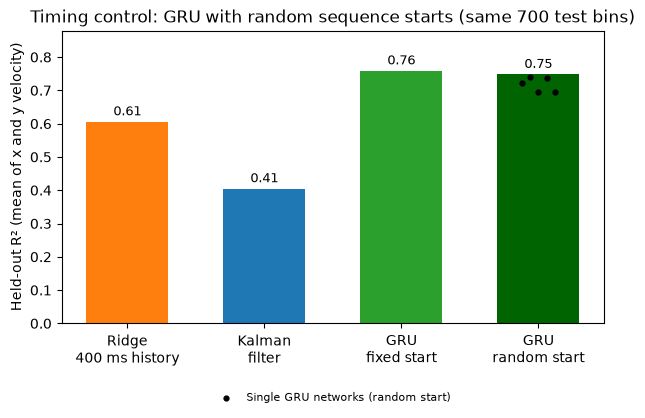

In [6]:
# Figure 14: does the GRU's advantage survive random sequence starts?
labels = list(PHASE4) + ["GRU\nrandom start"]
values = list(PHASE4.values()) + [ENSEMBLE["R² mean"]]
colors = ["tab:orange", "tab:blue", "tab:green", "darkgreen"]
fig, ax = plt.subplots(figsize=(7, 3.8))
bars = ax.bar(labels, values, color=colors, width=0.6)
for bar, v in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.01, f"{v:.2f}", ha="center", va="bottom", fontsize=9)
xg = bars[3].get_x() + bars[3].get_width() / 2
ax.scatter(np.full(N_SEEDS, xg) + np.linspace(-0.12, 0.12, N_SEEDS), seed_results["R² mean"],
           color="black", s=12, zorder=3, label="Single GRU networks (random start)")
ax.set_ylabel("Held-out R² (mean of x and y velocity)")
ax.set_title("Timing control: GRU with random sequence starts (same 700 test bins)")
ax.set_ylim(0, min(1.0, max(values) + 0.12))
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.2), frameon=False)
plt.savefig("../figures/14_gru_timing_control.png", dpi=150, bbox_inches="tight")

## Results to record

In [7]:
drop = PHASE4["GRU\nfixed start"] - ENSEMBLE["R² mean"]
print(f"GRU, random sequence starts ({N_SEEDS}-seed ensemble): held-out R² = {ENSEMBLE['R² mean']:.2f} "
      f"(x = {ENSEMBLE['R² x']:.2f}, y = {ENSEMBLE['R² y']:.2f}); fixed start was 0.76 (change: {-drop:+.2f})")

GRU, random sequence starts (5-seed ensemble): held-out R² = 0.75 (x = 0.83, y = 0.67); fixed start was 0.76 (change: -0.01)
